# Aula 04 · Vídeo 3 — Auditoria, Logs Imutáveis e Trilhas de Evidência

> **Disciplina:** Segurança, Guardrails e Conformidade para LLMs
> **Notebook conceitual + prático** — teoria do Documento 04 (seções 10-13) + código executável.

## Objetivos
- Explicar **auditabilidade** (ISO/IEC 27001 e 42001) e separação de funções — Doc 04, seções 10-12.
- Construir uma **hash chain** imutável e detectar adulterações:
$$ h_i = H\!\left(h_{i-1} \,\Vert\, \text{log}_i\right) $$
- Resumir a trilha com uma **Merkle tree** (Merkle, 1988) e discutir **WORM**.
- Priorizar risco com **CVSS-AI** ($R = P \cdot I$) e medir mitigação ($E = 1 - R_1/R_0$).

## 1. De confiança declarada a prova verificável

Encontrar falhas é apenas metade do trabalho (Doc 04, seção 10). A outra é **provar** o que
foi testado, quando, por quem, sob qual versão e como o sistema respondeu — a **auditabilidade**.
A **ISO/IEC 27001:2022** (segurança da informação) e a **ISO/IEC 42001:2023** (gestão de IA)
exigem controles documentados, responsabilidades claras e melhoria contínua. Um princípio
central: **quem administra a aplicação não deve conseguir apagar unilateralmente a evidência
de um incidente**.

In [1]:
import os
import sys
from pathlib import Path

_root = Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)  # resolve configs/ e data/ por caminho relativo

# Offline e determinístico (Restart & Run All): backend stub, sem rede/auditoria.
os.environ["LLM_BACKEND"] = "stub"
os.environ["AUDIT_ENABLED"] = "false"
os.environ.setdefault("GUARDRAIL_ENABLED", "true")
os.environ.setdefault("GUARDRAIL_NORMALIZE", "false")
os.environ.setdefault("GUARDRAIL_CONVERSATION", "false")
print("Ambiente pronto (offline). Raiz:", _root.name)

Ambiente pronto (offline). Raiz: aula04_testes_seguranca_auditoria


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from app.cvss_ai import cvss_ai_score, mitigation_effectiveness, score_finding, severity_band
from src.security.hash_chain import HashChain, genesis_hash
from src.security.merkle import merkle_root
print("Gênese h0 =", genesis_hash()[:24], "…")

Gênese h0 = ab1b49adb4e7b53350b704b7 …


## 2. Hash chains — encadeando a evidência (Doc 04, seção 11)

Cada registro incorpora o hash do anterior: $h_i = H(h_{i-1} \Vert \text{log}_i)$. Alterar um
registro antigo muda seu hash e **invalida toda a cadeia a partir dali**.

In [3]:
chain = HashChain()
chain.append({"action": "chat", "decision": "allow", "risk_score": 0.05, "conv": "conv-a1b2"})
chain.append({"action": "chat", "decision": "block", "risk_score": 0.90, "owasp": "LLM01"})
chain.append({"action": "tool_call", "decision": "block", "risk_score": 0.80, "owasp": "LLM08"})

v = chain.verify()
print(f"elos={v.count} | intacta={v.intact} | raiz de Merkle={v.merkle_root[:24]}…")
for e in chain.entries:
    print(f"  #{e.seq} {e.record['action']:9} {e.record['decision']:5} hash={e.hash[:12]}…")

elos=3 | intacta=True | raiz de Merkle=05380f9805d9512ae4df542c…
  #0 chat      allow hash=02642fe9d6c4…
  #1 chat      block hash=403112d8b0d5…
  #2 tool_call block hash=6d63aef60cdc…


## 3. Detecção de adulteração

Simulamos alguém tentando **encobrir um incidente**: mudar um `block` para `allow` no passado.
A verificação aponta exatamente o elo quebrado.

In [4]:
chain.entries[1].record["decision"] = "allow"   # adulteração retroativa
v2 = chain.verify()
print(f"intacta={v2.intact} | quebrou no elo={v2.broken_at}")
print("motivo:", v2.reason)

intacta=False | quebrou no elo=1
motivo: registro adulterado no elo 1 (hash não confere)


## 4. Merkle trees — resumindo a integridade (Merkle, 1988)

Uma **Merkle tree** resume N registros em uma única **raiz**. Publicar a raiz (ex.: em WORM)
permite provar depois que nada mudou: qualquer alteração de folha altera a raiz.

In [5]:
r1 = merkle_root(["evt1", "evt2", "evt3", "evt4"])
r2 = merkle_root(["evt1", "evt2", "evt3", "evt4"])
r3 = merkle_root(["evt1", "evt2", "evt3", "evt4-ADULTERADO"])
print("determinística:", r1 == r2)
print("sensível ao conteúdo:", r1 != r3)
print("raiz:", r1[:32], "…")

determinística: True
sensível ao conteúdo: True
raiz: 1b76e3c3bf3ccb7ebab9a1e9f938db6f …


## 5. WORM e persistência

**WORM** (*Write Once, Read Many*) garante que o dado escrito não seja alterado durante a
retenção. No lab, persistimos a cadeia em JSONL append-only; em produção o destino seria o
**Azure Blob Immutable Storage** (Doc 04, seção 11). Recarregar e reverificar deve manter a
integridade.

In [6]:
import tempfile

tmp = Path(tempfile.gettempdir()) / "aula04_chain_demo.jsonl"
chain2 = HashChain()
for i in range(3):
    chain2.append({"action": "chat", "decision": "allow", "seq_demo": i})
chain2.save(tmp)
recarregada = HashChain.load(tmp)
print("recarregada:", recarregada.verify())

recarregada: VerifyResult(intact=True, count=3, merkle_root='a363bfc7719b622fb7b3c266a277f9d4ba8feed7bef8a2113b24529fc347c37d', broken_at=None, reason='ok')


## 6. Observabilidade segura e SIEM (Doc 04, seção 12)

Logs ricos ajudam a investigar, mas podem conter dados sensíveis. Aplica-se **minimização**:
registramos **metadados** (versão do modelo, decisão, score, id **pseudonimizado**, **hash** da
entrada) — nunca o texto bruto. Eventos de maior risco vão a um **SIEM** (Microsoft Sentinel /
OpenSearch no lab).

In [7]:
evento_auditoria = {
    "action": "chat",
    "model_version": "aurora-assist-2.4.0",
    "decision": "block",
    "block_stage": "input",
    "owasp": "LLM01",
    "risk_score": 0.81,
    "conversation_id": "conv-3f2a9c1b7e0d",   # pseudonimizado (Doc 04, seção 12)
    "input_sha256": "9a1c4e77b2f0d3e5",        # hash, não o texto bruto (minimização)
}
print(pd.Series(evento_auditoria))

action                            chat
model_version      aurora-assist-2.4.0
decision                         block
block_stage                      input
owasp                            LLM01
risk_score                        0.81
conversation_id      conv-3f2a9c1b7e0d
input_sha256          9a1c4e77b2f0d3e5
dtype: object


## 7. Severidade CVSS-AI — priorizar com propósito (Doc 04, seção 13)

Nem todo achado tem a mesma urgência. Combinamos **probabilidade** (aprox. pela ASR) e
**impacto** por classe: $R = P \cdot I$, projetado em 0–10 (estilo CVSS v4.0).

In [8]:
achados = [score_finding(o, asr) for o, asr in [("LLM06", 0.02), ("LLM01", 0.33), ("LLM08", 0.20), ("LLM02", 0.15)]]
pd.DataFrame(achados)[["owasp", "asr", "impact", "score", "severity"]]

,owasp,asr,impact,score,severity
0,LLM06,0.02,1.0,0.2,low
1,LLM01,0.33,0.9,3.0,low
2,LLM08,0.20,0.9,1.8,low
3,LLM02,0.15,0.7,1.1,low


## 8. Matriz de severidade (probabilidade × impacto)

Reproduz a **Figura 3** do Documento 04: vazamento de dado no quadrante crítico; conteúdo
nocivo em médio/alto; desvio leve em baixo.

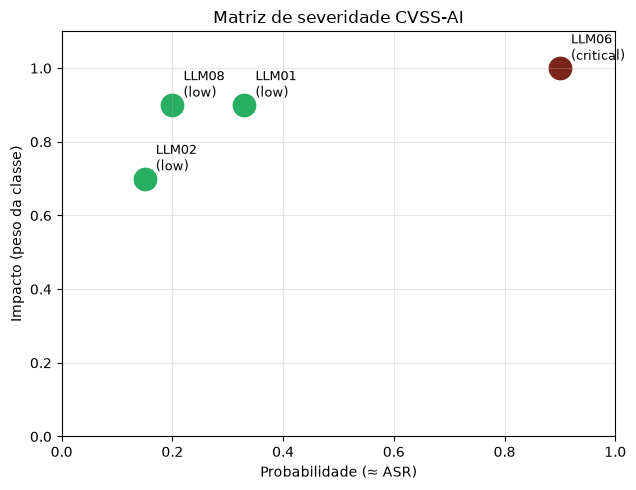

In [9]:
from app.cvss_ai import impact_weight

pontos = {"LLM06": 0.90, "LLM01": 0.33, "LLM08": 0.20, "LLM02": 0.15}
fig, ax = plt.subplots(figsize=(6.5, 5))
for owasp, p in pontos.items():
    i = impact_weight(owasp)
    sev = severity_band(cvss_ai_score(owasp, p))
    cor = {"critical": "#7b241c", "high": "#c0392b", "medium": "#e67e22", "low": "#27ae60", "none": "#95a5a6"}[sev]
    ax.scatter(p, i, s=260, color=cor)
    ax.annotate(f"{owasp}\n({sev})", (p, i), textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xlabel("Probabilidade (≈ ASR)")
ax.set_ylabel("Impacto (peso da classe)")
ax.set_title("Matriz de severidade CVSS-AI")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.1); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Efetividade da mitigação

Após corrigir, medimos $E = 1 - R_1/R_0$ (Doc 04, seção 13). Se a ASR de vazamento cai de 30%
para 2%, a mitigação é quase total.

In [10]:
for r0, r1 in [(0.30, 0.02), (0.30, 0.15), (0.33, 0.0)]:
    print(f"R0={r0:.0%}  R1={r1:.0%}  ->  E = {mitigation_effectiveness(r0, r1):.1%}")

R0=30%  R1=2%  ->  E = 93.3%
R0=30%  R1=15%  ->  E = 50.0%
R0=33%  R1=0%  ->  E = 100.0%


## Resumo e gancho para o Vídeo 4

Construímos evidência **verificável**: hash chains, Merkle, WORM, SIEM e severidade **CVSS-AI**.
No **Vídeo 4** integramos tudo em um **Lab End-to-End**: subimos a stack, medimos a campanha,
geramos o **relatório executivo** e comprovamos a **mitigação** ($E = 1 - R_1/R_0$).